In [31]:
from pathlib import Path
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import rankdata, spearmanr

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)

# parameter PROMETHEE II (ambang preferensi linear = kelipatan standar deviasi)
Q_FAKTOR = 0.5
P_FAKTOR = 2.0

# parameter evaluasi (sesuai bagian 7 proposal)
DELTA = (0.10, -0.10, 0.20, -0.20, 0.30, -0.30, 0.40, -0.40, 0.50, -0.50)  # skenario satu-per-satu (OAT)
N_MC = 1000                           # skenario acak (Monte Carlo): semua bobot diubah bersamaan
PERTURB = 0.5                         # tiap bobot dikalikan U(1-0,5 ; 1+0,5)
TOP_N = 10                            # untuk T10
N_UTAMA = 20                          # batas "wilayah teratas"
N_RR_ACAK = 500                       # pengulangan rank reversal dengan penghapusan acak
FRAKSI_HAPUS = 0.10                   # 10% alternatif dihapus pada uji acak
R_WAKTU = 30                          # pengulangan ukur waktu
SEED = 42

CSV = Path("data_kriteria_kabkota.csv")
if not CSV.exists():
    CSV = Path("/mnt/user-data/uploads/data_kriteria_kabkota.csv")
OUT = Path("hasil")
OUT.mkdir(exist_ok=True)

In [32]:
# 1. Pengumpulan data
df = pd.read_csv(CSV, encoding="utf-8-sig")

kode    = ["K-1", "K-2", "K-3", "K-4", "K-5", "K-6", "K-7", "K-8", "K-9", "K-10"]
kolom   = ["C01_populasi_2024", "C02_ntl_radiance_mean", "C03_ipm_2024", "C04_dist_to_primary_trunk_km",
           "C05_elevation_std_m", "C06_allsky_sfc_sw_dwn_mean", "C07_wind_speed_100m_mean_ms",
           "C08_pct_lahan_tersedia", "C09_pct_tree_cover", "C10_pct_ekosistem_sensitif"]
nama    = ["Populasi", "Kebutuhan Listrik", "IPM", "Jarak ke jalan arteri", "Variasi elevasi",
           "Radiasi surya", "Kecepatan angin 100 m", "Lahan tersedia", "Tutupan pohon", "Ekosistem sensitif"]
aspek   = ["Sosial ekonomi"] * 3 + ["Sumber daya"] * 5 + ["Lingkungan"] * 2
atribut = ["benefit", "benefit", "benefit", "cost", "cost", "benefit", "benefit", "benefit", "cost", "cost"]
pakai_log = [True, True, False, True, False, False, False, True, False, True]
n = len(kode)

print(df.shape, "| provinsi:", df["prov_name"].nunique())
print("nilai hilang :", df[kolom].isna().sum().sum())
print("kode ganda   :", df["bps_kabkota_code"].duplicated().sum())
print("nilai negatif:", (df[kolom] < 0).sum().sum())
df[kolom].describe().T.round(3)

(514, 16) | provinsi: 38
nilai hilang : 0
kode ganda   : 0
nilai negatif: 0


,count,mean,std,min,25%,50%,75%,max
C01_populasi_2024,514.0,547867.313,648960.571,24527.000,162867.500,298719.000,669965.750,5682303.000
C02_ntl_radiance_mean,514.0,3.377,7.292,0.147,0.327,0.590,2.413,63.878
C03_ipm_2024,514.0,71.919,6.288,36.300,68.865,71.685,75.000,88.770
C04_dist_to_primary_trunk_km,514.0,9.708,15.919,0.000,1.272,4.526,10.997,128.397
C05_elevation_std_m,514.0,253.097,211.973,2.296,69.188,230.201,392.245,1263.479
C06_allsky_sfc_sw_dwn_mean,514.0,207.860,12.116,184.839,199.013,204.259,214.536,250.325
C07_wind_speed_100m_mean_ms,514.0,3.209,0.784,1.690,2.636,3.082,3.691,5.978
C08_pct_lahan_tersedia,514.0,7.535,7.927,0.274,2.864,5.068,9.325,59.040
C09_pct_tree_cover,514.0,73.140,23.052,7.782,61.264,81.059,91.578,99.526
C10_pct_ekosistem_sensitif,514.0,1.646,3.368,0.000,0.008,0.332,1.517,29.644


In [33]:
# 2. Praproses data: transformasi log(1+x) pada variabel yang sangat miring
X = df[kolom].copy()
X.columns = kode
for k, l in zip(kode, pakai_log):
    if l:
        X[k] = np.log1p(X[k])

skew = pd.DataFrame({"kriteria": nama,
                     "skew_asli": df[kolom].skew().values,
                     "skew_sesudah": X.skew().values}, index=kode).round(3)
skew

,kriteria,skew_asli,skew_sesudah
K-1,Populasi,2.790,0.173
K-2,Kebutuhan Listrik,3.919,1.544
K-3,IPM,-0.767,-0.767
K-4,Jarak ke jalan arteri,3.945,0.334
K-5,Variasi elevasi,1.062,1.062
K-6,Radiasi surya,0.999,0.999
K-7,Kecepatan angin 100 m,0.803,0.803
K-8,Lahan tersedia,2.902,0.385
K-9,Tutupan pohon,-1.134,-1.134
K-10,Ekosistem sensitif,3.741,1.403


In [34]:
# 3. Pembobotan AHP
# tingkat kepentingan tiap kriteria (skala 1-9), dipakai untuk membentuk matriks perbandingan berpasangan
level = [3, 3, 2, 4, 3, 6, 5, 5, 2, 4]
A_manual = None      # isi dengan matriks 10x10 jika ingin memasukkan penilaian sendiri

A = np.ones((n, n))
for i in range(n):
    for j in range(n):
        d = level[i] - level[j]
        A[i, j] = min(1 + d, 9) if d >= 0 else 1 / min(1 - d, 9)
if A_manual is not None:
    A = np.array(A_manual, dtype=float)

A_norm = A / A.sum(axis=0)
w0 = A_norm.mean(axis=1)

lam = ((A @ w0) / w0).mean()
CI = (lam - n) / (n - 1)
RI = 1.49                     # Random Index untuk n = 10
CR = CI / RI
print(f"lambda maks = {lam:.4f}, CI = {CI:.4f}, CR = {CR:.4f}")
print("konsisten" if CR <= 0.1 else "TIDAK konsisten, perbaiki matriks")

bobot = pd.DataFrame({"kriteria": nama, "aspek": aspek, "atribut": atribut, "bobot": w0}, index=kode)
print(bobot.groupby("aspek")["bobot"].sum().round(4).to_string())
bobot.round(5)

lambda maks = 10.1125, CI = 0.0125, CR = 0.0084
konsisten
aspek
Lingkungan        0.1322
Sosial ekonomi    0.1491
Sumber daya       0.7186


,kriteria,aspek,atribut,bobot
K-1,Populasi,Sosial ekonomi,benefit,0.05724
K-2,Kebutuhan Listrik,Sosial ekonomi,benefit,0.05724
K-3,IPM,Sosial ekonomi,benefit,0.03464
K-4,Jarak ke jalan arteri,Sumber daya,cost,0.09758
K-5,Variasi elevasi,Sumber daya,cost,0.05724
K-6,Radiasi surya,Sumber daya,benefit,0.24517
K-7,Kecepatan angin 100 m,Sumber daya,benefit,0.15932
K-8,Lahan tersedia,Sumber daya,benefit,0.15932
K-9,Tutupan pohon,Lingkungan,cost,0.03464
K-10,Ekosistem sensitif,Lingkungan,cost,0.09758


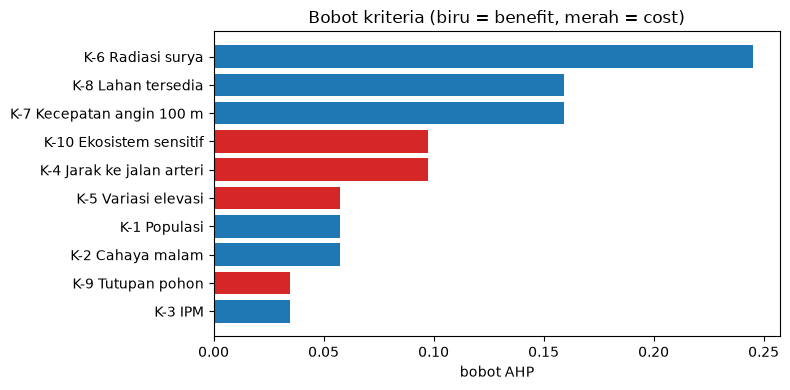

In [35]:
# grafik bobot AHP
b = bobot.sort_values("bobot")
warna = ["tab:red" if a == "cost" else "tab:blue" for a in b["atribut"]]
plt.figure(figsize=(8, 4))
plt.barh(b.index + " " + b["kriteria"], b["bobot"], color=warna)
plt.xlabel("bobot AHP")
plt.title("Bobot kriteria (biru = benefit, merah = cost)")
plt.tight_layout()
plt.savefig(OUT / "bobot_ahp.png", dpi=150)
plt.show()

In [36]:
# 4. Fungsi pemeringkatan TOPSIS dan PROMETHEE II
benefit = np.array([a == "benefit" for a in atribut])
Xm = X.to_numpy(float)
M = len(Xm)

def peringkat(skor):
    """peringkat 1 = skor tertinggi"""
    return rankdata(-skor, method="min").astype(int)

def topsis(Xd, w):
    """Xd: matriks keputusan (alternatif x kriteria), w: bobot. Mengembalikan nilai preferensi Vi."""
    R = Xd / np.sqrt((Xd ** 2).sum(axis=0))
    V = R * w
    ideal_pos = np.where(benefit, V.max(axis=0), V.min(axis=0))
    ideal_neg = np.where(benefit, V.min(axis=0), V.max(axis=0))
    dp = np.sqrt(((V - ideal_pos) ** 2).sum(axis=1))
    dn = np.sqrt(((V - ideal_neg) ** 2).sum(axis=1))
    return dn / (dp + dn)

def promethee(Xd, w):
    """PROMETHEE II dengan fungsi preferensi linear. Mengembalikan net flow."""
    m = len(Xd)
    sd = Xd.std(axis=0, ddof=1)
    q, p = Q_FAKTOR * sd, P_FAKTOR * sd
    Xb = np.where(benefit, Xd, -Xd)          # kriteria cost dibalik
    pi = np.zeros((m, m))
    for j in range(Xd.shape[1]):
        selisih = Xb[:, j][:, None] - Xb[:, j][None, :]
        pi += w[j] * np.clip((selisih - q[j]) / (p[j] - q[j]), 0, 1)
    fplus = pi.sum(axis=1) / (m - 1)
    fmin = pi.sum(axis=0) / (m - 1)
    return fplus - fmin

v_topsis = topsis(Xm, w0)
phi = promethee(Xm, w0)
rank_topsis = peringkat(v_topsis)
rank_prom = peringkat(phi)
print("V TOPSIS :", v_topsis.min().round(4), "-", v_topsis.max().round(4))
print("net flow :", phi.min().round(4), "-", phi.max().round(4), "| jumlah:", phi.sum().round(8))

V TOPSIS : 0.2927 - 0.8614
net flow : -0.4744 - 0.6902 | jumlah: 0.0


In [37]:
# 5. Tabel hasil pemeringkatan
hasil = pd.DataFrame({
    "kode_bps": df["bps_kabkota_code"],
    "kabkota": df["kabkota_name"],
    "provinsi": df["prov_name"],
    "jenis": df["jenis_wilayah"],
    "V_topsis": v_topsis,
    "peringkat_topsis": rank_topsis,
    "net_flow_promethee": phi,
    "peringkat_promethee": rank_prom,
})
hasil["selisih_peringkat"] = hasil["peringkat_topsis"] - hasil["peringkat_promethee"]
hasil["rata2_peringkat"] = (hasil["peringkat_topsis"] + hasil["peringkat_promethee"]) / 2
hasil = hasil.sort_values(["rata2_peringkat", "peringkat_topsis"]).reset_index(drop=True)

kol = ["kabkota", "provinsi", "V_topsis", "peringkat_topsis", "net_flow_promethee", "peringkat_promethee"]
print("Top 10 TOPSIS")
print(hasil.sort_values("peringkat_topsis").head(10)[kol].round(4).to_string(index=False))
print("\nTop 10 PROMETHEE II")
print(hasil.sort_values("peringkat_promethee").head(10)[kol].round(4).to_string(index=False))

Top 10 TOPSIS
        kabkota            provinsi  V_topsis  peringkat_topsis  net_flow_promethee  peringkat_promethee
    Kota Kupang Nusa Tenggara Timur    0.8614                 1              0.6902                    1
 Kota Pontianak    Kalimantan Barat    0.7707                 2              0.3193                   30
 Kota Palembang    Sumatera Selatan    0.7518                 3              0.2681                   47
    Sabu Raijua Nusa Tenggara Timur    0.7502                 4              0.5435                    2
   Kota Cirebon          Jawa Barat    0.7406                 5              0.3308                   27
           Belu Nusa Tenggara Timur    0.7375                 6              0.5199                    3
  Kota Parepare    Sulawesi Selatan    0.7363                 7              0.3883                   18
Kota Banda Aceh                Aceh    0.7284                 8              0.3348                   25
   Kota Mataram Nusa Tenggara Barat    0.

Spearman TOPSIS vs PROMETHEE II: 0.8279
irisan top-10: 4/10
irisan top-20: 11/20
irisan top-50: 29/50
selisih peringkat: rata-rata 68.6, median 59, maks 326


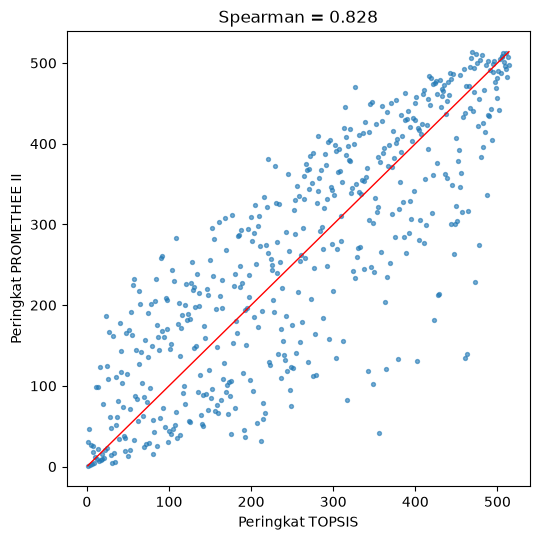

In [38]:
# 6. Kesesuaian urutan kedua metode
d = rank_topsis - rank_prom
rho = spearmanr(rank_topsis, rank_prom)[0]
print(f"Spearman TOPSIS vs PROMETHEE II: {rho:.4f}")
for t in (10, 20, 50):
    print(f"irisan top-{t}: {int(((rank_topsis <= t) & (rank_prom <= t)).sum())}/{t}")
print(f"selisih peringkat: rata-rata {np.abs(d).mean():.1f}, median {np.median(np.abs(d)):.0f}, maks {np.abs(d).max()}")

plt.figure(figsize=(5.5, 5.5))
plt.scatter(rank_topsis, rank_prom, s=8, alpha=0.6)
plt.plot([1, M], [1, M], color="red", lw=1)
plt.xlabel("Peringkat TOPSIS")
plt.ylabel("Peringkat PROMETHEE II")
plt.title(f"Spearman = {rho:.3f}")
plt.tight_layout()
plt.savefig(OUT / "perbandingan_peringkat.png", dpi=150)
plt.show()

In [39]:
# 7a. Stabilitas terhadap perubahan bobot
# (i) OAT: bobot satu kriteria diubah +-10%, 20%, 30%, 40%, 50% pada tiap dari 10 kriteria -> 100 skenario
# (ii) Monte Carlo: seluruh bobot diubah acak bersamaan -> N_MC skenario
def mars(r_s, r_0):
    return np.abs(r_s - r_0).mean()

def t10(r_s, r_0):
    return len(set(np.where(r_0 <= TOP_N)[0]) & set(np.where(r_s <= TOP_N)[0])) / TOP_N * 100

baris = []
rank_skenario = {"TOPSIS": [], "PROMETHEE II": []}

def jalankan_skenario(w, nama_skenario, kelompok):
    w = w / w.sum()                           # normalisasi ulang
    rt, rp = peringkat(topsis(Xm, w)), peringkat(promethee(Xm, w))
    rank_skenario["TOPSIS"].append(rt)
    rank_skenario["PROMETHEE II"].append(rp)
    baris.append({"skenario": nama_skenario, "kelompok": kelompok,
                  "MARS_TOPSIS": mars(rt, rank_topsis), "T10_TOPSIS": t10(rt, rank_topsis),
                  "MARS_PROMETHEE": mars(rp, rank_prom), "T10_PROMETHEE": t10(rp, rank_prom)})

for j in range(n):
    for dl in DELTA:
        w = w0.copy()
        w[j] *= (1 + dl)
        jalankan_skenario(w, f"{kode[j]} {dl:+.0%}", "OAT")

rng = np.random.default_rng(SEED)
for it in range(N_MC):
    jalankan_skenario(w0 * rng.uniform(1 - PERTURB, 1 + PERTURB, n), f"MC {it + 1}", "Monte Carlo")

stab = pd.DataFrame(baris)
print(stab["kelompok"].value_counts().to_string())
stab_ringkas = stab.drop(columns="skenario").groupby("kelompok").agg(["mean", "max"]).round(3).T
stab_ringkas

kelompok
Monte Carlo    1000
OAT             100


kelompok             Monte Carlo      OAT
MARS_TOPSIS    mean       39.579   10.628
               max        78.556   49.953
T10_TOPSIS     mean       70.110   91.900
               max       100.000  100.000
MARS_PROMETHEE mean       17.308    5.284
               max        34.879   21.121
T10_PROMETHEE  mean       82.520   95.600
               max       100.000  100.000

In [40]:
# 7b. Standar deviasi skor akhir (skor dinormalisasi min-max ke 0-1 lebih dulu)
def minmax(s):
    return (s - s.min()) / (s.max() - s.min())

sd_topsis = minmax(v_topsis).std(ddof=1)
sd_prom = minmax(phi).std(ddof=1)
sd_tabel = pd.DataFrame({"metode": ["TOPSIS", "PROMETHEE II"], "SD skor ternormalisasi": [sd_topsis, sd_prom]})
sd_tabel.round(4)

,metode,SD skor ternormalisasi
0,TOPSIS,0.1381
1,PROMETHEE II,0.1711


In [41]:
# 7c. Rank reversal
# (i) leave-one-out: tiap kabupaten/kota dihapus satu per satu (514 uji, seluruh alternatif)
# (ii) penghapusan acak sebesar FRAKSI_HAPUS dari alternatif, diulang N_RR_ACAK kali
def proporsi_berbalik(s_lama, s_baru):
    """proporsi pasangan alternatif yang urutannya berbalik"""
    a = np.sign(s_lama[:, None] - s_lama[None, :])
    b = np.sign(s_baru[:, None] - s_baru[None, :])
    berbalik = ((a * b) < 0).sum() / 2
    m = len(s_lama)
    return berbalik / (m * (m - 1) / 2)

def uji_rr(daftar_hapus):
    rt, rp = [], []
    for hapus in daftar_hapus:
        sisa = np.delete(np.arange(M), hapus)
        rt.append(proporsi_berbalik(v_topsis[sisa], topsis(Xm[sisa], w0)))
        rp.append(proporsi_berbalik(phi[sisa], promethee(Xm[sisa], w0)))
    return np.array(rt), np.array(rp)

rng_rr = np.random.default_rng(SEED)
loo_t, loo_p = uji_rr([[i] for i in range(M)])
k_hapus = int(round(FRAKSI_HAPUS * M))
acak_t, acak_p = uji_rr([rng_rr.choice(M, k_hapus, replace=False) for _ in range(N_RR_ACAK)])

rr = pd.DataFrame({
    "uji": [f"Leave-one-out ({M} uji)"] * 2 + [f"Hapus {k_hapus} acak ({N_RR_ACAK} ulangan)"] * 2,
    "metode": ["TOPSIS", "PROMETHEE II"] * 2,
    "RR rata-rata": [loo_t.mean(), loo_p.mean(), acak_t.mean(), acak_p.mean()],
    "RR maks": [loo_t.max(), loo_p.max(), acak_t.max(), acak_p.max()],
    "% uji tanpa pembalikan": [(loo_t == 0).mean() * 100, (loo_p == 0).mean() * 100,
                               (acak_t == 0).mean() * 100, (acak_p == 0).mean() * 100]})
rr.round(6)

,uji,metode,RR rata-rata,RR maks,% uji tanpa pembalikan
0,Leave-one-out (514 uji),TOPSIS,0.000452,0.005856,0.0
1,Leave-one-out (514 uji),PROMETHEE II,0.000227,0.001218,0.0
2,Hapus 51 acak (500 ulangan),TOPSIS,0.004522,0.017120,0.0
3,Hapus 51 acak (500 ulangan),PROMETHEE II,0.002041,0.004974,0.0


In [42]:
# 7d. Waktu komputasi tahap pemeringkatan saja (tanpa pemuatan data dan AHP), R = 30 pengulangan
def ukur_waktu(fungsi):
    fungsi(Xm, w0)                            # pemanasan
    t = []
    for _ in range(R_WAKTU):
        t0 = time.perf_counter()
        peringkat(fungsi(Xm, w0))
        t.append(time.perf_counter() - t0)
    return np.mean(t), np.std(t, ddof=1)

wt, st = ukur_waktu(topsis)
wp, sp = ukur_waktu(promethee)
waktu = pd.DataFrame({"metode": ["TOPSIS", "PROMETHEE II"],
                      "waktu rata-rata (detik)": [wt, wp], "simpangan baku (detik)": [st, sp]})
waktu.round(5)

,metode,waktu rata-rata (detik),simpangan baku (detik)
0,TOPSIS,0.00020,0.00006
1,PROMETHEE II,0.03033,0.00268


In [43]:
# 8. Wilayah yang konsisten berada di posisi teratas pada kedua metode
mat_t = np.vstack(rank_skenario["TOPSIS"])        # (100 OAT + MC) x M
mat_p = np.vstack(rank_skenario["PROMETHEE II"])
frek = pd.DataFrame({"kode_bps": df["bps_kabkota_code"],
                     "frek_topsis": (mat_t <= N_UTAMA).mean(axis=0),
                     "frek_promethee": (mat_p <= N_UTAMA).mean(axis=0)})
hasil = hasil.merge(frek, on="kode_bps")
hasil["frek_min"] = hasil[["frek_topsis", "frek_promethee"]].min(axis=1)

ok = (hasil["peringkat_topsis"] <= N_UTAMA) & (hasil["peringkat_promethee"] <= N_UTAMA)
konsisten = hasil[ok].sort_values("rata2_peringkat")[
    ["kabkota", "provinsi", "peringkat_topsis", "peringkat_promethee",
     "frek_topsis", "frek_promethee", "frek_min"]].reset_index(drop=True)
print(len(konsisten), f"wilayah masuk top-{N_UTAMA} di kedua metode")
print((konsisten["frek_min"] >= 0.8).sum(), f"di antaranya tetap di top-{N_UTAMA} pada >= 80% dari seluruh skenario bobot")
konsisten

11 wilayah masuk top-20 di kedua metode
3 di antaranya tetap di top-20 pada >= 80% dari seluruh skenario bobot


,kabkota,provinsi,peringkat_topsis,peringkat_promethee,frek_topsis,frek_promethee,frek_min
0,Kota Kupang,Nusa Tenggara Timur,1,1,1.000000,1.000000,1.000000
1,Sabu Raijua,Nusa Tenggara Timur,4,2,0.860909,1.000000,0.860909
2,Belu,Nusa Tenggara Timur,6,3,0.812727,1.000000,0.812727
3,Kota Mataram,Nusa Tenggara Barat,9,4,0.785455,1.000000,0.785455
4,Kota Bima,Nusa Tenggara Barat,10,12,0.755455,0.985455,0.755455
5,Pamekasan,Jawa Timur,12,10,0.758182,1.000000,0.758182
6,Timor Tengah Selatan,Nusa Tenggara Timur,15,7,0.563636,0.997273,0.563636
7,Kota Parepare,Sulawesi Selatan,7,18,0.921818,0.780909,0.780909
8,Sumba Tengah,Nusa Tenggara Timur,17,8,0.540909,0.968182,0.540909
9,Timor Tengah Utara,Nusa Tenggara Timur,18,9,0.543636,0.975455,0.543636


In [44]:
# 9. Ringkasan perbandingan empat dimensi
def rata(kelompok, kolom):
    return stab.loc[stab["kelompok"] == kelompok, kolom].mean()

ringkasan = pd.DataFrame({
    "Dimensi": ["Stabilitas OAT: MARS (lebih kecil lebih baik)",
                "Stabilitas OAT: T10 % (lebih besar lebih baik)",
                "Stabilitas Monte Carlo: MARS (lebih kecil lebih baik)",
                "Stabilitas Monte Carlo: T10 % (lebih besar lebih baik)",
                "SD skor ternormalisasi (lebih besar lebih membedakan)",
                "Rank reversal leave-one-out, RR (lebih kecil lebih baik)",
                "Rank reversal hapus acak, RR (lebih kecil lebih baik)",
                "Waktu komputasi, detik (lebih kecil lebih efisien)"],
    "AHP-TOPSIS": [rata("OAT", "MARS_TOPSIS"), rata("OAT", "T10_TOPSIS"),
                   rata("Monte Carlo", "MARS_TOPSIS"), rata("Monte Carlo", "T10_TOPSIS"),
                   sd_topsis, loo_t.mean(), acak_t.mean(), wt],
    "AHP-PROMETHEE II": [rata("OAT", "MARS_PROMETHEE"), rata("OAT", "T10_PROMETHEE"),
                         rata("Monte Carlo", "MARS_PROMETHEE"), rata("Monte Carlo", "T10_PROMETHEE"),
                         sd_prom, loo_p.mean(), acak_p.mean(), wp]})
ringkasan.round(5)

,Dimensi,AHP-TOPSIS,AHP-PROMETHEE II
0,Stabilitas OAT: MARS (lebih kecil lebih baik),10.62829,5.28374
1,Stabilitas OAT: T10 % (lebih besar lebih baik),91.90000,95.60000
2,Stabilitas Monte Carlo: MARS (lebih kecil lebi...,39.57883,17.30760
3,Stabilitas Monte Carlo: T10 % (lebih besar leb...,70.11000,82.52000
4,SD skor ternormalisasi (lebih besar lebih memb...,0.13810,0.17110
5,"Rank reversal leave-one-out, RR (lebih kecil l...",0.00045,0.00023
6,"Rank reversal hapus acak, RR (lebih kecil lebi...",0.00452,0.00204
7,"Waktu komputasi, detik (lebih kecil lebih efis...",0.00020,0.03033


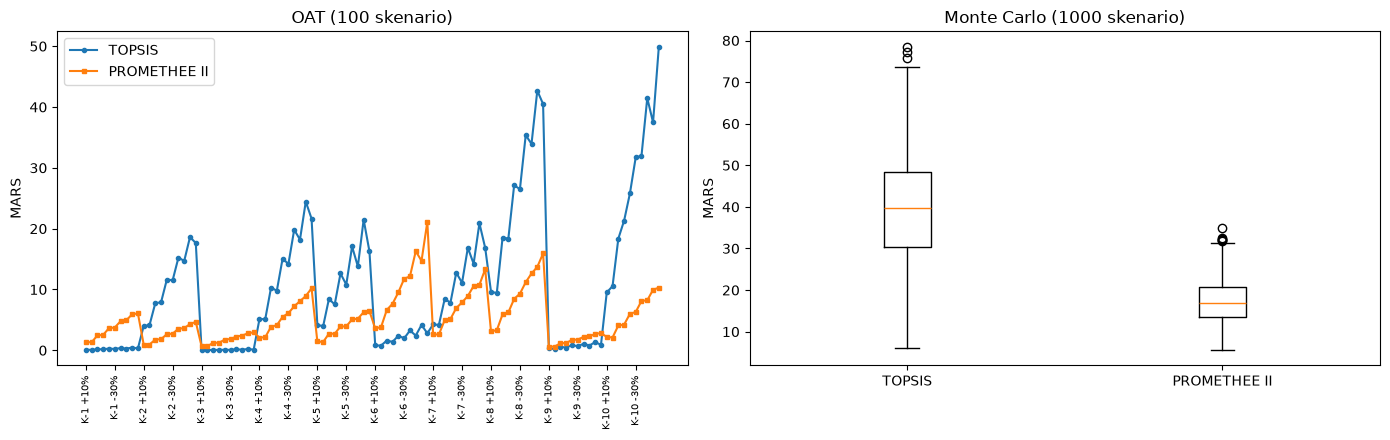

In [45]:
# grafik stabilitas
fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
oat = stab[stab.kelompok == "OAT"].reset_index(drop=True)
ax[0].plot(oat["MARS_TOPSIS"].values, "o-", ms=3, label="TOPSIS")
ax[0].plot(oat["MARS_PROMETHEE"].values, "s-", ms=3, label="PROMETHEE II")
ax[0].set_xticks(range(0, len(oat), 5), oat["skenario"][::5], rotation=90, fontsize=7)
ax[0].set_ylabel("MARS")
ax[0].set_title(f"OAT ({len(oat)} skenario)")
ax[0].legend()

mc = stab[stab.kelompok == "Monte Carlo"]
ax[1].boxplot([mc["MARS_TOPSIS"], mc["MARS_PROMETHEE"]], tick_labels=["TOPSIS", "PROMETHEE II"])
ax[1].set_ylabel("MARS")
ax[1].set_title(f"Monte Carlo ({len(mc)} skenario)")
plt.tight_layout()
plt.savefig(OUT / "stabilitas_bobot.png", dpi=150)
plt.show()

## 10. Hasil Evaluasi Perbandingan Metode AHP-TOPSIS dan AHP-PROMETHEE II (Dimensi 0–7)

Bagian ini menampilkan tabel perbandingan 8 dimensi evaluasi (0–7) dari hasil perhitungan aktual, visualisasi grafik batang, serta kesimpulan komparatif kedua metode.

In [ ]:
# Tabel perbandingan hasil evaluasi dimensi 0-7 dari variabel hasil perhitungan aktual
dimensi_spec = [
    (0, 'Stabilitas OAT: MARS', float(rata('OAT', 'MARS_TOPSIS')), float(rata('OAT', 'MARS_PROMETHEE')), 'min'),
    (1, 'Stabilitas OAT: T10 (%)', float(rata('OAT', 'T10_TOPSIS')), float(rata('OAT', 'T10_PROMETHEE')), 'max'),
    (2, 'Stabilitas Monte Carlo: MARS', float(rata('Monte Carlo', 'MARS_TOPSIS')), float(rata('Monte Carlo', 'MARS_PROMETHEE')), 'min'),
    (3, 'Stabilitas Monte Carlo: T10 (%)', float(rata('Monte Carlo', 'T10_TOPSIS')), float(rata('Monte Carlo', 'T10_PROMETHEE')), 'max'),
    (4, 'SD skor ternormalisasi', float(sd_topsis), float(sd_prom), 'spread'),
    (5, 'Rank reversal leave-one-out (RR)', float(loo_t.mean()), float(loo_p.mean()), 'min'),
    (6, 'Rank reversal hapus acak (RR)', float(acak_t.mean()), float(acak_p.mean()), 'min'),
    (7, 'Waktu komputasi (detik)', float(wt), float(wp), 'min'),
]

def tentukan_unggulan(v_topsis, v_prom, arah):
    if np.isclose(v_topsis, v_prom, atol=1e-12):
        return 'Setara'
    if arah == 'min':
        return 'AHP-TOPSIS' if v_topsis < v_prom else 'AHP-PROMETHEE II'
    if arah == 'max':
        return 'AHP-TOPSIS' if v_topsis > v_prom else 'AHP-PROMETHEE II'
    lebih_besar = 'AHP-TOPSIS' if v_topsis > v_prom else 'AHP-PROMETHEE II'
    return f'Penyebaran lebih besar: {lebih_besar}'

baris_eval = []
for no, nama_dim, vt, vp, arah in dimensi_spec:
    baris_eval.append({
        'No': no,
        'Dimensi Evaluasi': nama_dim,
        'AHP-TOPSIS': round(vt, 5),
        'AHP-PROMETHEE II': round(vp, 5),
        'Metode yang Lebih Unggul': tentukan_unggulan(vt, vp, arah),
    })

tabel_evaluasi = pd.DataFrame(baris_eval)
print(tabel_evaluasi.to_string(index=False, formatters={
    'AHP-TOPSIS': '{:.5f}'.format,
    'AHP-PROMETHEE II': '{:.5f}'.format,
}))
tabel_evaluasi.style.format({'AHP-TOPSIS': '{:.5f}', 'AHP-PROMETHEE II': '{:.5f}'}).hide(axis='index')

In [ ]:
# Visualisasi grafik batang 8 dimensi evaluasi (0-7)
subjudul_arah = {
    'min': 'Lebih kecil lebih baik',
    'max': 'Lebih besar lebih baik',
    'spread': 'Lebih besar = penyebaran skor lebih luas',
}

fig, axes = plt.subplots(2, 4, figsize=(16, 8))
axes = axes.ravel()

for idx, (no, nama_dim, vt, vp, arah) in enumerate(dimensi_spec):
    ax = axes[idx]
    vals = [vt, vp]
    bars = ax.bar(['AHP-TOPSIS', 'AHP-PROMETHEE II'], vals, color=['#426650', '#DF7848'], width=0.55)
    ax.set_title(f'{no}. {nama_dim}\n({subjudul_arah[arah]})', fontsize=9.5, fontweight='bold')
    ax.grid(axis='y', linestyle='--', alpha=0.35)
    ymax = max(vals) if max(vals) > 0 else 1.0
    ax.set_ylim(0, ymax * 1.24)
    for b, val in zip(bars, vals):
        fmt = f'{val:.2f}' if no in (1, 3) else f'{val:.5f}'
        ax.text(b.get_x() + b.get_width() / 2, val + ymax * 0.03, fmt,
                ha='center', va='bottom', fontsize=8.5, fontweight='bold')

plt.suptitle('Perbandingan Evaluasi Metode AHP-TOPSIS vs AHP-PROMETHEE II (Dimensi 0–7)', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig(OUT / 'evaluasi_0_7.png', dpi=150)
plt.show()

In [ ]:
# Kesimpulan hasil evaluasi dimensi 0-7 berdasarkan nilai aktual
d = {no: (nama_dim, vt, vp, tentukan_unggulan(vt, vp, arah)) for no, nama_dim, vt, vp, arah in dimensi_spec}

print('=== INTERPRETASI HASIL EVALUASI (0–7) ===')
print(f"0. Stabilitas OAT (MARS): AHP-TOPSIS = {d[0][1]:.5f}, AHP-PROMETHEE II = {d[0][2]:.5f} -> MARS lebih rendah: {d[0][3]}.")
print(f"1. Stabilitas OAT (T10 %): AHP-TOPSIS = {d[1][1]:.5f}%, AHP-PROMETHEE II = {d[1][2]:.5f}% -> T10 lebih tinggi: {d[1][3]}.")
print(f"2. Stabilitas Monte Carlo (MARS): AHP-TOPSIS = {d[2][1]:.5f}, AHP-PROMETHEE II = {d[2][2]:.5f} -> MARS lebih rendah: {d[2][3]}.")
print(f"3. Stabilitas Monte Carlo (T10 %): AHP-TOPSIS = {d[3][1]:.5f}%, AHP-PROMETHEE II = {d[3][2]:.5f}% -> T10 lebih tinggi: {d[3][3]}.")
print(f"4. SD skor ternormalisasi: AHP-TOPSIS = {d[4][1]:.5f}, AHP-PROMETHEE II = {d[4][2]:.5f} -> {d[4][3]} (menunjukkan penyebaran skor yang lebih besar, bukan ukuran akurasi keseluruhan).")
print(f"5. Rank reversal leave-one-out (RR): AHP-TOPSIS = {d[5][1]:.5f}, AHP-PROMETHEE II = {d[5][2]:.5f} -> RR lebih rendah: {d[5][3]}.")
print(f"6. Rank reversal hapus acak (RR): AHP-TOPSIS = {d[6][1]:.5f}, AHP-PROMETHEE II = {d[6][2]:.5f} -> RR lebih rendah: {d[6][3]}.")
print(f"7. Waktu komputasi (detik): AHP-TOPSIS = {d[7][1]:.5f} dtk, AHP-PROMETHEE II = {d[7][2]:.5f} dtk -> Waktu lebih singkat: {d[7][3]}.")

print('\n=== KESIMPULAN AKHIR ===')
print(
    f"Berdasarkan kedelapan dimensi evaluasi (0–7), masing-masing metode menunjukkan keunggulan pada aspek berbeda: "
    f"{d[0][3]} memiliki pergeseran peringkat (MARS) yang lebih rendah pada uji OAT ({d[0][1]:.5f} vs {d[0][2]:.5f}) "
    f"dan Monte Carlo ({d[2][1]:.5f} vs {d[2][2]:.5f}), serta mempertahankan irisan Top-10 (T10) lebih tinggi pada uji OAT ({d[1][3]}) dan Monte Carlo ({d[3][3]}). "
    f"Pada uji konsistensi terhadap penghapusan alternatif, {d[5][3]} mencatat rank reversal lebih rendah pada skenario leave-one-out "
    f"({d[5][1]:.5f} vs {d[5][2]:.5f}) dan {d[6][3]} pada penghapusan acak ({d[6][1]:.5f} vs {d[6][2]:.5f}). "
    f"Untuk sebaran nilai, {d[4][3]} ({d[4][1]:.5f} vs {d[4][2]:.5f}) sehingga perbedaan antar-alternatif lebih terentang, "
    f"sedangkan dari sisi efisiensi eksekusi, {d[7][3]} jauh lebih cepat ({min(d[7][1], d[7][2]):.5f} detik)."
)
